# Project 9: Optimizer Comparison Using a Neural Network

**Goal:** Train the same small neural network on the Iris dataset twice, changing only the optimizer, then compare how it learns and how well it classifies unseen flowers.

We will use **Stochastic Gradient Descent (SGD)** and **Adam**. The experiment uses a fixed train/test split so the comparison is fair and repeatable.

## Task 1: Build a Simple Neural Network Using the Iris Dataset

Iris contains 150 flower samples. Each sample has four measurements, and the target is one of three species. We keep 20% of the data for final testing.

The scaler is placed inside a pipeline so it is fitted only on the training data. This avoids letting test-set information leak into training.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 21

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Total samples: {len(X)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print("Input features:", ", ".join(iris.feature_names))
print("Classes:", ", ".join(iris.target_names))

Total samples: 150
Training samples: 120
Testing samples: 30
Input features: sepal length (cm), sepal width (cm), petal length (cm), petal width (cm)
Classes: setosa, versicolor, virginica


### Build the Neural Network Model

Both models use the same architecture: **4 input features → 8 hidden neurons → 3 output classes**. ReLU is used in the hidden layer and the output layer uses the classifier's standard probability-based classification setup.

To keep the comparison focused, we use the same split, random seed, hidden-layer size, and training limit. The optimizer and its learning-rate setting are the main differences.

In [2]:
common_settings = {
    "hidden_layer_sizes": (8,),
    "activation": "relu",
    "solver": "sgd",          # replaced for the Adam experiment below
    "learning_rate_init": 0.03,
    "max_iter": 500,
    "random_state": SEED,
    "tol": 1e-5
}

# SGD model
sgd_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(**common_settings, momentum=0.0)
)

# Adam model: same network and data, different optimizer
adam_settings = common_settings.copy()
adam_settings["solver"] = "adam"
adam_settings["learning_rate_init"] = 0.01

adam_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(**adam_settings)
)

sgd_model.fit(X_train, y_train)
adam_model.fit(X_train, y_train)

sgd_net = sgd_model.named_steps["mlpclassifier"]
adam_net = adam_model.named_steps["mlpclassifier"]

print("SGD training iterations:", sgd_net.n_iter_)
print("Adam training iterations:", adam_net.n_iter_)

SGD training iterations: 500
Adam training iterations: 500


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


## Task 2: Train the Model Using SGD and Adam Optimizers

The loss curve shows the training loss recorded during learning. A curve that falls more quickly is reducing training error faster, but the test-set results still matter: low training loss alone does not guarantee better predictions on new data.

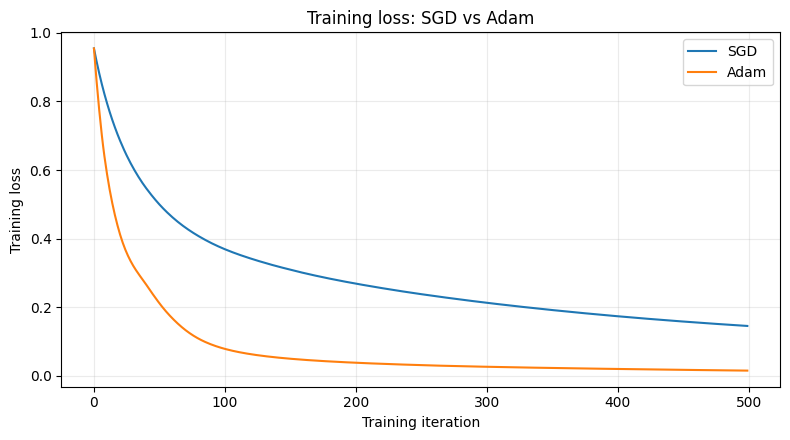

SGD  — final training loss: 0.1457
Adam — final training loss: 0.0155


In [3]:
plt.figure(figsize=(8, 4.5))
plt.plot(sgd_net.loss_curve_, label="SGD")
plt.plot(adam_net.loss_curve_, label="Adam")
plt.xlabel("Training iteration")
plt.ylabel("Training loss")
plt.title("Training loss: SGD vs Adam")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"SGD  — final training loss: {sgd_net.loss_curve_[-1]:.4f}")
print(f"Adam — final training loss: {adam_net.loss_curve_[-1]:.4f}")

## Task 3: Compare Training Results and Classification Performance

We now evaluate both trained models on the same held-out test set. Accuracy is the share of test flowers classified correctly. The classification report also gives precision, recall, and F1-score for each species.

In [4]:
pred_sgd = sgd_model.predict(X_test)
pred_adam = adam_model.predict(X_test)

results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Test accuracy": [
        accuracy_score(y_test, pred_sgd),
        accuracy_score(y_test, pred_adam)
    ],
    "Final training loss": [
        sgd_net.loss_curve_[-1],
        adam_net.loss_curve_[-1]
    ],
    "Iterations used": [sgd_net.n_iter_, adam_net.n_iter_]
})

display(results.style.format({
    "Test accuracy": "{:.2%}",
    "Final training loss": "{:.4f}"
}))

print("SGD classification report")
print(classification_report(y_test, pred_sgd, target_names=iris.target_names, zero_division=0))

print("Adam classification report")
print(classification_report(y_test, pred_adam, target_names=iris.target_names, zero_division=0))

,Optimizer,Test accuracy,Final training loss,Iterations used
0,SGD,96.67%,0.1457,500
1,Adam,96.67%,0.0155,500


SGD classification report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Adam classification report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



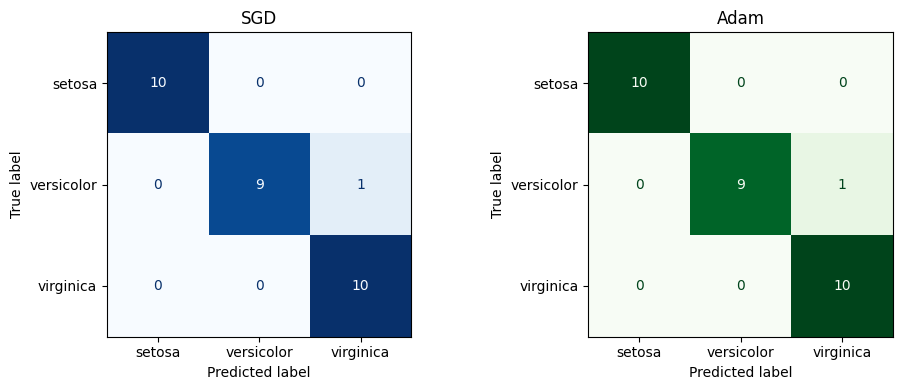

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_sgd, display_labels=iris.target_names,
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("SGD")
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_adam, display_labels=iris.target_names,
    cmap="Greens", colorbar=False, ax=axes[1]
)
axes[1].set_title("Adam")
plt.tight_layout()
plt.show()

## Conclusion

Use the table and plots above to write the conclusion from your actual run:

- **Training behavior:** Compare the shape of the two loss curves and each model's final training loss.
- **Classification:** Compare the test accuracies and the per-class precision/recall/F1 scores.
- **Interpretation:** Adam often makes useful progress with less learning-rate tuning because it adapts parameter updates. SGD is simpler, and its performance depends strongly on its learning rate and other settings.
- **Important limitation:** This is one train/test split and one set of hyperparameters. If one optimizer wins here, that does not prove it is always better. A stronger study would repeat the experiment across several seeds and compare average results.

**Conclusion template:** “In this run, ___ had the higher test accuracy (___ versus ___). The loss curves show ___. Therefore, for this particular network setup and split, ___ performed better overall. The result is specific to these settings rather than a universal rule.”